In [ ]:
!pip install -q transformers==5.8.0

In [ ]:
from transformers import AutoModelForImageTextToText

model = AutoModelForImageTextToText.from_pretrained("google/gemma-4-E4B-it")
print(type(model))
# <class 'transformers.models.gemma4.modeling_gemma4.Gemma4ForConditionalGeneration'>

# The multimodal components live under model.model:
print(model.model.vision_tower.__class__.__name__)   # Gemma4VisionModel
print(model.model.embed_vision.__class__.__name__)    # Gemma4MultimodalEmbedder
print(model.model.language_model.__class__.__name__)  # Gemma4TextModel

# Count parameters in each component:
def count_params(module):
    return sum(p.numel() for p in module.parameters())

print(f"\nVision tower:  {count_params(model.model.vision_tower) / 1e6:.1f}M params")
print(f"Projector:     {count_params(model.model.embed_vision) / 1e6:.1f}M params")
print(f"Language model: {count_params(model.model.language_model) / 1e6:.1f}M params")

Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

<class 'transformers.models.gemma4.modeling_gemma4.Gemma4ForConditionalGeneration'>
Gemma4VisionModel
Gemma4MultimodalEmbedder
Gemma4TextModel

Vision tower:  167.4M params
Projector:     2.0M params
Language model: 7463.0M params


In [ ]:
from transformers import AutoModelForImageTextToText

model = AutoModelForImageTextToText.from_pretrained("google/gemma-4-E4B-it")

# Show all top-level submodules
for name, module in model.named_children():
    print(f"{name}: {module.__class__.__name__}")

Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/208 [00:00<?, ?B/s]

model: Gemma4Model
lm_head: Linear


In [ ]:
for name, module in model.model.named_children():
    print(f"{name}: {module.__class__.__name__}")

vision_tower: Gemma4VisionModel
language_model: Gemma4TextModel
audio_tower: Gemma4AudioModel
embed_vision: Gemma4MultimodalEmbedder
embed_audio: Gemma4MultimodalEmbedder


In [ ]:
# Check the actual hidden dimensions
print(f"Vision hidden size: {model.model.vision_tower.config.hidden_size}")
print(f"Language hidden size: {model.model.language_model.config.hidden_size}")

# Also check patch size
print(f"Patch size: {model.model.vision_tower.config.patch_size}")

Vision hidden size: 768
Language hidden size: 2560
Patch size: 16


In [ ]:
!pip install --upgrade "datasets>=4.7.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 17.1 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninstalling datasets-4.0.0:
      Successfully uninstalled datasets-4.0.0


In [ ]:
# chapter11/code/download_dataset.py
from datasets import load_dataset

dataset = load_dataset("lmoroney/uiscreenshots")

# Save locally for training
dataset["train"].to_json("./data/ui_vision_dataset_train.jsonl")
dataset["validation"].to_json("./data/ui_vision_dataset_val.jsonl")
print(f"Train: {len(dataset['train'])} examples")
print(f"Val:   {len(dataset['validation'])} examples")

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Train: 225 examples
Val:   25 examples


Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Train: 225 examples
Val:   25 examples
Image path: images/ui_screenshots/ui_home_feed_028.png
Prompt: Describe the UI layout and elements in this screenshot.



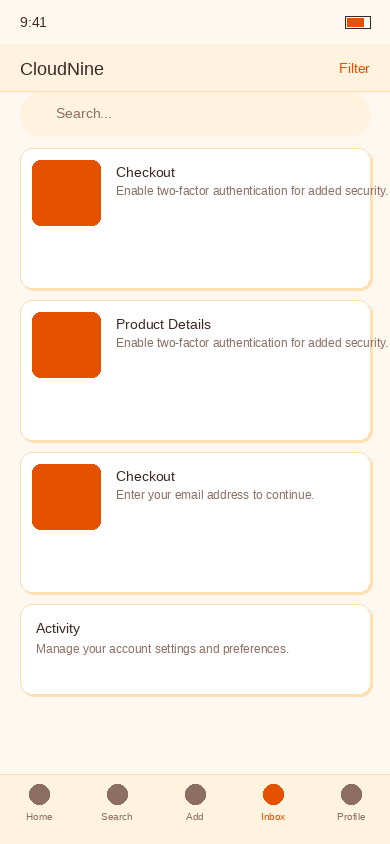

Image size: (390, 844), mode: RGB


In [ ]:
# chapter11/code/download_dataset.py
from datasets import load_dataset
from PIL import Image
import requests
from io import BytesIO
from IPython.display import display

REPO_ID = "lmoroney/uiscreenshots"
HUB_BASE = f"https://huggingface.co/datasets/{REPO_ID}/resolve/main/"

dataset = load_dataset(REPO_ID)

# Save locally for training
dataset["train"].to_json("./data/ui_vision_dataset_train.jsonl")
dataset["validation"].to_json("./data/ui_vision_dataset_val.jsonl")
print(f"Train: {len(dataset['train'])} examples")
print(f"Val:   {len(dataset['validation'])} examples")


def extract_image_path(example):
    """Find the first image entry in the user message and return its relative path."""
    for msg in example["messages"]:
        if msg["role"] != "user":
            continue
        for part in msg["content"]:
            if part.get("type") == "image":
                # Field might be "url", "path", or "image" depending on the dataset
                return part.get("url") or part.get("path") or part.get("image")
    return None


def extract_user_prompt(example):
    for msg in example["messages"]:
        if msg["role"] == "user":
            for part in msg["content"]:
                if part.get("type") == "text":
                    return part["text"]
    return None


def load_image(relative_path):
    url = HUB_BASE + relative_path.lstrip("/")
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    return Image.open(BytesIO(resp.content))


# Display the first example
example = dataset["train"][0]
rel_path = extract_image_path(example)
print(f"Image path: {rel_path}")
print(f"Prompt: {extract_user_prompt(example)}\n")

img = load_image(rel_path)
display(img)
print(f"Image size: {img.size}, mode: {img.mode}")